# Déployez un modèle dans le cloud


# Sommaire :

**1. Préambule**<br />
&emsp;1.1 Problématique<br />
&emsp;1.2 Objectifs dans ce projet<br />
&emsp;1.3 Déroulement des étapes du projet<br />
**2. Choix techniques généraux retenus**<br />
&emsp;2.1 Calcul distribué<br />
&emsp;2.2 Transfert Learning<br />
**3. Déploiement de la solution en local**<br />
&emsp;3.1 Environnement de travail<br />
&emsp;3.2 Installation de Spark<br />
&emsp;3.3 Installation des packages<br />
&emsp;3.4 Import des librairies<br />
&emsp;3.5 Définition des PATH pour charger les images   et enregistrer les résultats<br />
&emsp;3.6 Création de la SparkSession<br />
&emsp;3.7 Traitement des données<br />
&emsp;&emsp;3.7.1 Chargement des données<br />
&emsp;&emsp;3.7.2 Préparation du modèle<br />
&emsp;&emsp;3.7.3 Définition du processus de chargement des images et application  de leur featurisation à travers l'utilisation de pandas UDF<br />
&emsp;&emsp;3.7.4 Exécution des actions d'extraction de features<br />
&emsp;&emsp;3.7.5 Réduction de dimension avec une PCA en PySpark<br />
&emsp;3.8 Chargement des données enregistrées et validation du résultat<br />
**4. Déploiement de la solution sur le cloud**<br />
&emsp;4.1 Les briques d'une architecture Big Data<br />
&emsp;4.2 Choix des outils : AWS EMR et S3<br />
&emsp;4.3 Conformité au RGPD<br />
&emsp;4.4 Configuration de l'environnement de travail<br />
&emsp;4.5 Chargement des données sur S3<br />
&emsp;4.6 Configuration du serveur EMR<br />
&emsp;4.7 Instanciation du serveur<br />
&emsp;4.8 Création du tunnel SSH vers la machine primaire<br />
&emsp;4.9 Connexion au notebook JupyterHub<br />
&emsp;4.10 Exécution du code<br />
&emsp;&emsp;4.10.1 Démarrage de la session Spark<br />
&emsp;&emsp;4.10.2 Installation des packages<br />
&emsp;&emsp;4.10.3 Import des librairies<br />
&emsp;&emsp;4.10.4 Définition des PATH pour charger les images et enregistrer les résultats<br />
&emsp;&emsp;4.10.5 Traitement des données<br />
&emsp;&emsp;&emsp;4.10.5.1 Chargement des données<br />
&emsp;&emsp;&emsp;4.10.5.2 Préparation du modèle et diffusion des poids<br />
&emsp;&emsp;&emsp;4.10.5.3 Définition du processus de chargement des images   et application de leur featurisation à travers l'utilisation de pandas UDF<br />
&emsp;&emsp;&emsp;4.10.5.4 Exécutions des actions d'extractions de features<br />
&emsp;&emsp;&emsp;4.10.5.5 Réduction de dimension (PCA) sur le cluster<br />
&emsp;&emsp;4.10.6 Chargement des données enregistrées et validation du résultat<br />
&emsp;4.11 Suivi de l'exécution avec le Spark History Server<br />
&emsp;4.12 Résiliation de l'instance EMR<br />
&emsp;4.13 Recréer le cluster (si besoin)<br />
&emsp;4.14 Arborescence du bucket S3 à la fin du projet<br />
**5. Conclusion**<br />
&emsp;5.1 Synthèse<br />
&emsp;5.2 Traitements critiques lors du passage à l'échelle<br />
&emsp;5.3 Regard critique<br />
&emsp;5.4 Correspondance avec le référentiel d'évaluation<br />

# 1. Préambule

## 1.1 Problématique

La très jeune start-up de l'AgriTech, nommée "**Fruits**!", <br />
cherche à proposer des solutions innovantes pour la récolte des fruits.

La volonté de l’entreprise est de préserver la biodiversité des fruits <br />
en permettant des traitements spécifiques pour chaque espèce de fruits <br />
en développant des robots cueilleurs intelligents.

La start-up souhaite dans un premier temps se faire connaître en mettant <br />
à disposition du grand public une application mobile qui permettrait aux <br />
utilisateurs de prendre en photo un fruit et d'obtenir des informations sur ce fruit.

Pour la start-up, cette application permettrait de sensibiliser le grand public <br /> 
à la biodiversité des fruits et de mettre en place une première version du moteur <br />
de classification des images de fruits.

De plus, le développement de l’application mobile permettra de construire <br />
une première version de l'architecture **Big Data** nécessaire.

## 1.2 Objectifs dans ce projet

1. Développer une première chaîne de traitement des données qui <br />
   comprendra le **preprocessing** et une étape de **réduction de dimension**.
2. Tenir compte du fait que <u>le volume de données va augmenter <br />
   très rapidement</u> après la livraison de ce projet, ce qui implique de:
 - Déployer le traitement des données dans un environnement **Big Data**
 - Développer les scripts en **pyspark** pour effectuer du **calcul distribué**

## 1.3 Déroulement des étapes du projet

Le projet va être réalisé en 2 temps, dans deux environnements différents. <br />
Nous allons dans un premier temps développer et exécuter notre code en local, <br />
en travaillant sur un nombre limité d'images à traiter.

Une fois les choix techniques validés, nous déploierons notre solution <br />
dans un environnement Big Data en mode distribué.

<u>Pour cette raison, ce projet sera divisé en 3 parties</u>:
1. Liste des choix techniques généraux retenus
2. Déploiement de la solution en local
3. Déploiement de la solution dans le cloud

# 2. Choix techniques généraux retenus

## 2.1 Calcul distribué

L’énoncé du projet nous impose de développer des scripts en **pyspark** <br />
afin de <u>prendre en compte l’augmentation très rapide du volume <br />
de donné après la livraison du projet</u>.

Pour comprendre rapidement et simplement ce qu’est **pyspark** <br />
et son principe de fonctionnement, nous vous conseillons de lire <br />
cet article : [PySpark : Tout savoir sur la librairie Python](https://datascientest.com/pyspark)

<u>Le début de l’article nous dit ceci </u>:<br />
« *Lorsque l’on parle de traitement de bases de données sur python, <br />
on pense immédiatement à la librairie pandas. Cependant, lorsqu’on a <br />
affaire à des bases de données trop massives, les calculs deviennent trop lents.<br />
Heureusement, il existe une autre librairie python, assez proche <br />
de pandas, qui permet de traiter des très grandes quantités de données : PySpark.<br />
Apache Spark est un framework open-source développé par l’AMPLab <br />
de UC Berkeley permettant de traiter des bases de données massives <br />
en utilisant le calcul distribué, technique qui consiste à exploiter <br />
plusieurs unités de calcul réparties en clusters au profit d’un seul <br />
projet afin de diviser le temps d’exécution d’une requête.<br />
Spark a été développé en Scala et est au meilleur de ses capacités <br />
dans son langage natif. Cependant, la librairie PySpark propose de <br />
l’utiliser avec le langage Python, en gardant des performances <br />
similaires à des implémentations en Scala.<br />
Pyspark est donc une bonne alternative à la librairie pandas lorsqu’on <br />
cherche à traiter des jeux de données trop volumineux qui entraînent <br />
des calculs trop chronophages.* »

Comme nous le constatons, **pySpark** est un moyen de communiquer <br />
avec **Spark** via le langage **Python**.<br />
**Spark**, quant à lui, est un outil qui permet de gérer et de coordonner <br />
l'exécution de tâches sur des données à travers un groupe d'ordinateurs. <br />
<u>Spark (ou Apache Spark) est un framework open source de calcul distribué <br />
in-memory pour le traitement et l'analyse de données massives</u>.

Un autre [article très intéressant et beaucoup plus complet pour <br />
comprendre le **fonctionnement de Spark**](https://www.veonum.com/apache-spark-pour-les-nuls/), ainsi que le rôle <br />
des **Spark Session** que nous utiliserons dans ce projet.

<u>Voici également un extrait</u>:

*Les applications Spark se composent d’un pilote (« driver process ») <br />
et de plusieurs exécuteurs (« executor processes »). Il peut être configuré <br />
pour être lui-même l’exécuteur (local mode) ou en utiliser autant que <br />
nécessaire pour traiter l’application, Spark prenant en charge la mise <br />
à l’échelle automatique par une configuration d’un nombre minimum <br />
et maximum d’exécuteurs.*

![Schéma de Spark](img/spark-schema.png)

*Le driver (parfois appelé « Spark Session ») distribue et planifie <br />
les tâches entre les différents exécuteurs qui les exécutent et permettent <br />
un traitement réparti. Il est le responsable de l’exécution du code <br />
sur les différentes machines.

Chaque exécuteur est un processus Java Virtual Machine (JVM) distinct <br />
dont il est possible de configurer le nombre de CPU et la quantité de <br />
mémoire qui lui est alloué. <br />
Une seule tâche peut traiter un fractionnement de données à la fois.*

Dans les deux environnements (Local et Cloud) nous utiliserons donc **Spark** <br />
et nous l’exploiterons à travers des scripts python grâce à **PySpark**.

Dans la <u>version locale</u> de notre script nous **simulerons <br />
le calcul distribué** afin de valider que notre solution fonctionne.<br />
Dans la <u>version cloud</u> nous **réaliserons les opérations sur un cluster de machine**.

## 2.2 Transfert Learning

L'énoncé du projet nous demande également de <br />
réaliser une première chaîne de traitement <br />
des données qui comprendra le preprocessing et <br />
une étape de réduction de dimension.

Il est également précisé qu'il n'est pas nécessaire <br />
d'entraîner un modèle pour le moment.

Nous décidons de partir sur une solution de **transfert learning**.

Simplement, le **transfert learning** consiste <br />
à utiliser la connaissance déjà acquise <br />
par un modèle entraîné (ici **MobileNetV2**) pour <br />
l'adapter à notre problématique.

Nous allons fournir au modèle nos images, et nous allons <br />
<u>récupérer l'avant dernière couche</u> du modèle.<br />
En effet la dernière couche de modèle est une couche softmax <br />
qui permet la classification des images ce que nous ne <br />
souhaitons pas dans ce projet.

L'avant dernière couche correspond à un **vecteur <br />
réduit** de dimension (1,1,1280).

Cela permettra de réaliser une première version du moteur <br />
pour la classification des images des fruits.

**MobileNetV2** a été retenu pour sa <u>rapidité d'exécution</u>, <br />
particulièrement adaptée pour le traitement d'un gros volume <br />
de données ainsi que la <u>faible dimensionnalité du vecteur <br />
de caractéristique en sortie</u> (1,1,1280)

# 3. Déploiement de la solution en local

## 3.1 Environnement de travail

Nous développons dans un environnement **Linux Ubuntu** (sous Windows : **WSL2**, le sous-système Linux de Windows,
plus simple et plus rapide qu'une machine virtuelle).

Spark est un programme Java piloté depuis Python : il faut donc **Java 17**.
Spark 3.5 ne fonctionne pas avec Java 21 (l'extraction des features échoue avec
`UnsupportedOperationException: sun.misc.Unsafe or java.nio.DirectByteBuffer ... not available`).
EMR 7 utilise aussi Java 17 : l'environnement local et le cluster sont identiques.

## 3.2 Installation de Spark

Spark est installé avec le package Python **pyspark**, qui contient Spark : aucune installation séparée n'est nécessaire.

## 3.3 Installation des packages

Les versions sont **figées** : ce sont exactement celles installées sur le cluster EMR par le script
de bootstrap (section 4.6). Ce qui fonctionne en local fonctionne donc sur le cluster.

In [1]:
%pip install pyspark==3.5.3 tensorflow-cpu==2.16.2 keras==3.5.0 numpy==1.26.4 pandas==2.2.3 pyarrow==17.0.0 pillow==10.4.0 matplotlib

Note: you may need to restart the kernel to use updated packages.


## 3.4 Import des librairies

In [2]:
import io
import os
import time
from typing import Iterator

import numpy as np
import pandas as pd
from PIL import Image

import tensorflow as tf
from keras.applications.mobilenet_v2 import MobileNetV2, preprocess_input
from keras import Model

from pyspark.sql import SparkSession
from pyspark.sql.functions import col, pandas_udf, element_at, split
from pyspark.ml.functions import array_to_vector, vector_to_array
from pyspark.ml.feature import StandardScaler, PCA

2026-11-14 22:29:35.632855: I tensorflow/core/util/port.cc:113] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-11-14 22:29:35.984079: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


## 3.5 Définition des PATH pour charger les images <br /> et enregistrer les résultats

Les données et les résultats sont dans le dossier personnel Linux (`~/p8`), plus rapide que `/mnt/c` sous WSL.
L'échantillon local `Test_local` contient **10 variétés x 150 images = 1 500 images** : assez pour que les
chiffres de la PCA aient un sens (avec n images, au plus n-1 composantes portent de la variance).

In [3]:
# Data and results live in the Linux home folder (fast), whatever folder Jupyter starts in.
PATH = os.path.expanduser('~/p8')
PATH_Data = PATH+'/data/Test_local'                  # local sample: 10 varieties x 150 images
PATH_Result = PATH+'/output/Results'                 # features (1280 values)
PATH_PCA = PATH+'/output/Results_PCA'                # features after PCA
PATH_Variance = PATH+'/output/Results_PCA_variance'  # explained variance (CSV)
print('PATH:          '+PATH+
      '\nPATH_Data:     '+PATH_Data+
      '\nPATH_Result:   '+PATH_Result+
      '\nPATH_PCA:      '+PATH_PCA+
      '\nPATH_Variance: '+PATH_Variance)

PATH:          /home/darya/p8
PATH_Data:     /home/darya/p8/data/Test_local
PATH_Result:   /home/darya/p8/output/Results
PATH_PCA:      /home/darya/p8/output/Results_PCA
PATH_Variance: /home/darya/p8/output/Results_PCA_variance


## 3.6 Création de la SparkSession

L'application Spark est contrôlée par un processus de pilotage (le **driver**) via la **SparkSession**.
Une SparkSession correspond toujours à une application Spark.

<u>Nous créons la session en spécifiant</u> :
 1. un **nom pour l'application** ("P8"), affiché dans l'interface web de Spark ;
 2. **`local[4]`** : exécution locale sur **4 cœurs**. Chaque cœur exécute sa propre copie de TensorFlow
    et son propre lot d'images : avec tous les cœurs, la mémoire allouée à WSL est dépassée ;
 3. **4 Go de mémoire** : en local, driver et exécuteurs partagent le même processus Java ;
 4. **256 images par lot Arrow** : chaque image décodée occupe environ 0,6 Mo ; la valeur par défaut
    (10 000 lignes) demanderait environ 6 Go par lot ;
 5. une **option Java** nécessaire à Apache Arrow (utilisé par les pandas UDF) avec Java 17 ;
 6. l'option d'écriture **parquet** de la version précédente, conservée.

In [4]:
# Number of cores used locally. Each core runs its own copy of TensorFlow and its own batch of images.
# If a cell fails with "Python worker exited unexpectedly" or "Answer from Java side is empty",
# lower N_CORES to 2 (memory), restart the kernel and run again.
N_CORES = 4

ARROW_JAVA_OPTION = "-Dio.netty.tryReflectionSetAccessible=true"

spark = (SparkSession
             .builder
             .appName('P8')
             .master(f'local[{N_CORES}]')
             .config("spark.driver.memory", "4g")
             .config("spark.sql.execution.arrow.maxRecordsPerBatch", "256")
             .config("spark.driver.extraJavaOptions", ARROW_JAVA_OPTION)
             .config("spark.executor.extraJavaOptions", ARROW_JAVA_OPTION)
             .config("spark.sql.parquet.writeLegacyFormat", 'true')
             .getOrCreate()
)

your 131072x1 screen size is bogus. expect trouble
26/11/14 22:30:30 WARN Utils: Your hostname, PLG-5CD4485137 resolves to a loopback address: 127.0.1.1; using 10.255.255.254 instead (on interface lo)
26/11/14 22:30:30 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/11/14 22:30:30 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


<u>Nous créons également la variable "**sc**" qui est un **SparkContext** issue de la variable **spark**</u> :

In [5]:
sc = spark.sparkContext

<u>Affichage des informations de Spark en cours d'execution</u> :

In [6]:
spark

## 3.7 Traitement des données

<u>Dans la suite de notre flux de travail, <br />
nous allons successivement</u> :
1. Préparer nos données
    1. Importer les images dans un dataframe **pandas UDF**
    2. Associer aux images leur **label**
    3. Préprocesser en **redimensionnant nos images pour <br />
       qu'elles soient compatibles avec notre modèle**
2. Préparer notre modèle
    1. Importer le modèle **MobileNetV2**
    2. Créer un **nouveau modèle** dépourvu de la dernière couche de MobileNetV2
3. Définir le processus de chargement des images et l'application <br />
   de leur featurisation à travers l'utilisation de pandas UDF
3. Exécuter les actions d'extraction de features
4. Enregistrer le résultat de nos actions
5. Tester le bon fonctionnement en chargeant les données enregistrées




### 3.7.1 Chargement des données

Les images sont chargées au format binaire, ce qui offre, <br />
plus de souplesse dans la façon de prétraiter les images.

Avant de charger les images, nous spécifions que nous voulons charger <br />
uniquement les fichiers dont l'extension est **jpg**.

Nous indiquons également de charger tous les objets possibles contenus <br />
dans les sous-dossiers du dossier communiqué.

In [7]:
images = spark.read.format("binaryFile") \
  .option("pathGlobFilter", "*.jpg") \
  .option("recursiveFileLookup", "true") \
  .load(PATH_Data)

<u>Affichage des 5 premières images contenant</u> :
 - le path de l'image
 - la date et heure de sa dernière modification
 - sa longueur
 - son contenu encodé en valeur hexadécimal

<u>Je ne conserve que le **path** de l'image et j'ajoute <br />
    une colonne contenant les **labels** de chaque image</u> :

In [8]:
images = images.withColumn('label', element_at(split(images['path'], '/'),-2))
print(images.printSchema())
print(images.select('path','label').show(5,False))

root
 |-- path: string (nullable = true)
 |-- modificationTime: timestamp (nullable = true)
 |-- length: long (nullable = true)
 |-- content: binary (nullable = true)
 |-- label: string (nullable = true)

None
+--------------------------------------------------------------+--------------+
|path                                                          |label         |
+--------------------------------------------------------------+--------------+
|file:/home/darya/p8/data/Test_local/Apple Golden 1/114_100.jpg|Apple Golden 1|
|file:/home/darya/p8/data/Test_local/Apple Golden 1/103_100.jpg|Apple Golden 1|
|file:/home/darya/p8/data/Test_local/Apple Golden 1/101_100.jpg|Apple Golden 1|
|file:/home/darya/p8/data/Test_local/Apple Golden 1/96_100.jpg |Apple Golden 1|
|file:/home/darya/p8/data/Test_local/Apple Golden 1/100_100.jpg|Apple Golden 1|
+--------------------------------------------------------------+--------------+
only showing top 5 rows

None


In [9]:
n_images = images.count()   # action: Spark lists and reads the files now
n_labels = images.select("label").distinct().count()
print(n_images, "images,", n_labels, "classes")

1492 images, 10 classes


### 3.7.2 Préparation du modèle

Je vais utiliser la technique du **transfert learning** pour extraire les features des images.<br />
J'ai choisi d'utiliser le modèle **MobileNetV2** pour sa rapidité d'exécution comparée <br />
à d'autres modèles comme *VGG16* par exemple.

Pour en savoir plus sur la conception et le fonctionnement de MobileNetV2, <br />
je vous invite à lire [cet article](https://towardsdatascience.com/review-mobilenetv2-light-weight-model-image-classification-8febb490e61c).

<u>Voici le schéma de son architecture globale</u> : 

![Architecture de MobileNetV2](img/mobilenetv2_architecture.png)

Il existe une dernière couche qui sert à classer les images <br />
selon 1000 catégories que nous ne voulons pas utiliser.<br />
L'idée dans ce projet est de récupérer le **vecteur de caractéristiques <br />
de dimensions (1,1,1280)** qui servira, plus tard, au travers d'un moteur <br />
de classification à reconnaitre les différents fruits du jeu de données.

Comme d'autres modèles similaires, **MobileNetV2**, lorsqu'on l'utilise <br />
en incluant toutes ses couches, attend obligatoirement des images <br />
de dimension (224,224,3). Nos images étant toutes de dimension (100,100,3), <br />
nous devrons simplement les **redimensionner** avant de les confier au modèle.

<u>Dans l'odre</u> :
 1. Nous chargeons le modèle **MobileNetV2** avec les poids **précalculés** <br />
    issus d'**imagenet** et en spécifiant le format de nos images en entrée
 2. Nous créons un nouveau modèle avec:
  - <u>en entrée</u> : l'entrée du modèle MobileNetV2
  - <u>en sortie</u> : l'avant dernière couche du modèle MobileNetV2

In [10]:
model = MobileNetV2(weights='imagenet',
                    include_top=True,
                    input_shape=(224, 224, 3))

14536120/14536120 ━━━━━━━━━━━━━━━━━━━━ 4s 0us/step


In [11]:
new_model = Model(inputs=model.input,
                  outputs=model.layers[-2].output)

Affichage du résumé de notre nouveau modèle où nous constatons <br />
que <u>nous récupérons bien en sortie un vecteur de dimension (1, 1, 1280)</u> :

In [12]:
new_model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1 (Conv2D)      │ (None, 112, 112,  │        864 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_Conv1            │ (None, 112, 112,  │        128 │ Conv1[0][0]       │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1_relu (ReLU)   │ (None, 112, 112,  │          0 │ bn_Conv1[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        288 │ Conv1_relu[0][0]  │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        128 │ expanded_conv_de… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │          0 │ expanded_conv_de… │
│ (ReLU)              │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │        512 │ expanded_conv_de… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │         64 │ expanded_conv_pr… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand      │ (None, 112, 112,  │      1,536 │ expanded_conv_pr… │
│ (Conv2D)            │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_BN   │ (None, 112, 112,  │        384 │ block_1_expand[0… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_relu │ (None, 112, 112,  │          0 │ block_1_expand_B… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_pad         │ (None, 113, 113,  │          0 │ block_1_expand_r… │
│ (ZeroPadding2D)     │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise   │ (None, 56, 56,    │        864 │ block_1_pad[0][0] │
│ (DepthwiseConv2D)   │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │        384 │ block_1_depthwis… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │          0 │ block_1_depthwis… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_project     │ (None, 56, 56,    │      2,304 │ block_1_depthwis

 Total params: 2,257,984 (8.61 MB)

 Trainable params: 2,223,872 (8.48 MB)

 Non-trainable params: 34,112 (133.25 KB)

#### Diffusion des poids du modèle (broadcast)

Les **exécuteurs** (workers) sont des processus distincts du driver, souvent sur d'autres machines :
ils ne voient pas les objets créés dans ce notebook. Chacun a besoin du modèle. Or un modèle, c'est :
- une **architecture** (la liste des couches) : du code, que chaque exécuteur peut reconstruire en une seconde ;
- des **poids** : environ 9 Mo de nombres appris sur ImageNet, qu'il faut **transporter**.

Le **broadcast** envoie les poids **une seule fois à chaque exécuteur**, qui les garde en mémoire pour
toutes ses tâches. `get_weights()` renvoie une simple liste de tableaux NumPy, que Spark sait envoyer.

In [13]:
weights = new_model.get_weights()
bc_weights = sc.broadcast(weights)

print(len(weights), "tableaux de poids,",
      round(sum(w.nbytes for w in weights) / 1e6, 1), "Mo diffusés")

260 tableaux de poids, 9.0 Mo diffusés


<u>Fonction exécutée sur chaque exécuteur</u> : elle reconstruit le modèle **à partir des poids diffusés**.

**Correction de la version précédente** : la fonction construisait le modèle avec `weights='imagenet'`.
Chaque exécuteur **téléchargeait donc les poids depuis Internet**, puis les remplaçait par les poids
diffusés : le broadcast existait mais ne servait à rien, et les exécuteurs avaient besoin d'un accès Internet.

Avec `weights=None`, l'architecture est construite **vide** (valeurs aléatoires, **aucun téléchargement**),
puis `set_weights` la remplit avec la copie locale des poids diffusés (`bc_weights.value`).
La boucle `layer.trainable = False` est supprimée : elle n'a aucun effet en inférence.

In [14]:
def model_fn():
    """
    Executed on each executor: rebuilds MobileNetV2 without its last layer,
    WITHOUT downloading anything, and loads the broadcast weights.
    """
    model = MobileNetV2(weights=None,          # architecture only: no download
                        include_top=True,
                        input_shape=(224, 224, 3))
    new_model = Model(inputs=model.input,
                      outputs=model.layers[-2].output)
    new_model.set_weights(bc_weights.value)    # local copy of the broadcast weights
    return new_model

<u>Vérification</u> : le modèle reconstruit par `model_fn()` à partir des poids diffusés doit donner
**exactement** les mêmes résultats que le modèle du driver. Nous comparons les sorties sur deux images aléatoires.

In [ ]:
test_images = np.random.rand(2, 224, 224, 3).astype("float32")
same = np.allclose(new_model.predict(test_images, verbose=0),
                   model_fn().predict(test_images, verbose=0), atol=1e-5)
print("Modèle reconstruit à partir des poids diffusés identique :", same)

### 3.7.3 Définition du processus de chargement des images et application <br/>de leur featurisation à travers l'utilisation de pandas UDF

Spark ne sait pas exécuter un réseau de neurones avec ses fonctions intégrées. Une **pandas UDF**
est une fonction Python que Spark appelle sur des **lots** d'images (`pd.Series`), transmis au format
rapide Apache Arrow.

<u>L'empilement des appels est le suivant</u> :

- `featurize_udf` (pandas UDF **itérative**) : reconstruit le modèle **une fois par tâche** avec `model_fn()`,
  puis le réutilise pour chaque lot ;
  - `featurize_series` : un seul appel au réseau pour tout le lot ;
    - `preprocess` : décode une image, **force 3 canaux RGB** (une photo de téléphone peut être en niveaux de gris
      ou en PNG avec transparence), redimensionne en 224 x 224 et met les pixels à l'échelle [-1, 1].

<u>Modernisation</u> : `PandasUDFType.SCALAR_ITER` est obsolète depuis Spark 3.0 ; la forme actuelle utilise
des annotations de type (`Iterator[pd.Series] -> Iterator[pd.Series]`).

In [15]:
def preprocess(content):
    """
    Preprocesses raw image bytes for prediction.
    """
    img = Image.open(io.BytesIO(content)).convert("RGB").resize([224, 224])
    arr = np.asarray(img, dtype=np.float32)
    return preprocess_input(arr)

def featurize_series(model, content_series):
    """
    Featurize a pd.Series of raw images using the input model.
    :return: a pd.Series of image features
    """
    input = np.stack(content_series.map(preprocess).to_list())
    preds = model.predict(input, verbose=0)
    output = [p.flatten().astype(np.float32) for p in preds]
    return pd.Series(output)

@pandas_udf('array<float>')
def featurize_udf(content_series_iter: Iterator[pd.Series]) -> Iterator[pd.Series]:
    """
    Scalar iterator pandas UDF: the model is rebuilt ONCE per task from the
    broadcast weights, then reused for every batch of images.
    """
    model = model_fn()
    for content_series in content_series_iter:
        yield featurize_series(model, content_series)

### 3.7.4 Exécution des actions d'extraction de features

La taille des lots Arrow a été fixée à **256 images** dans la SparkSession (section 3.6) :
un lot occupe alors environ 150 Mo en mémoire, au lieu d'environ 6 Go avec la valeur par défaut (10 000).
La version précédente laissait ce réglage en commentaire, ce qui provoque des erreurs de mémoire (OOM) à grande échelle.

In [16]:
print("Images par lot Arrow :", spark.conf.get("spark.sql.execution.arrow.maxRecordsPerBatch"))

Images par lot Arrow : 256


Nous pouvons maintenant exécuter la featurisation sur l'ensemble de notre DataFrame Spark.

`repartition` répartit les images en **2 partitions par cœur** disponible (au lieu de la valeur fixe 20) :
le même code s'adapte au nombre de cœurs du portable comme du cluster.

<u>REMARQUE</u> : cette cellule s'exécute instantanément, car Spark est **paresseux** (*lazy*) :
le calcul n'a lieu qu'à l'écriture du résultat.

In [17]:
features_df = images.repartition(2 * sc.defaultParallelism).select(col("path"),
                                            col("label"),
                                            featurize_udf("content").alias("features")
                                           )

<u>Rappel du PATH où seront inscrits les fichiers au format "**parquet**" <br />
contenant nos résultats, à savoir, un DataFrame contenant 3 colonnes</u> :
 1. Path des images
 2. Label de l'image
 3. Vecteur de caractéristiques de l'image

In [18]:
print(PATH_Result)

/home/darya/p8/output/Results


<u>Enregistrement des données traitées au format "**parquet**"</u> :

In [19]:
t0 = time.time()
features_df.write.mode("overwrite").parquet(PATH_Result)
seconds_features = round(time.time() - t0, 1)
print(f"Extraction des features : {seconds_features} s")

2026-11-14 22:36:09.338468: I tensorflow/core/util/port.cc:113] oneDNN custom operations are on. You may see slightly different 2026-11-14 22:36:09.338467: I tensorflow/core/util/port.cc:113] oneDNN custom operations are on. You may see slightly different 2026-11-14 22:36:09.338467: I tensorflow/core/util/port.cc:113] oneDNN custom operations are on. You may see slightly different 2026-11-14 22:36:09.338468: I tensorflow/core/util/port.cc:113] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environmennumerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environmennumerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
t variable `TF_ENABLE_ONEDNN_OPTS=0`.
t variable `TF_ENABLE_ONEDNN

Extraction des features : 17.0 s


### 3.7.5 Réduction de dimension avec une PCA en PySpark

Chaque image est décrite par **1280 valeurs**. Une **PCA** (analyse en composantes principales) les résume
en **k composantes** qui conservent l'essentiel de l'information : stockage plus léger et futur classifieur plus rapide.
Elle est calculée avec **Spark ML**, donc de façon distribuée : son coût augmente avec le nombre d'images,
tandis que la matrice de covariance reste de taille 1280 x 1280.

<u>Trois étapes</u> :
1. **Conversion et centrage** : Spark ML travaille sur des *vecteurs* (`array_to_vector`). La projection de la PCA
   de Spark **ne soustrait pas la moyenne** : nous centrons d'abord les données avec
   `StandardScaler(withMean=True, withStd=False)` (centrage sans changement d'échelle).
2. **Choix de k** : une PCA à 300 composantes donne la part de variance expliquée par chacune ;
   nous retenons le plus petit **k** qui conserve **90 %** de la variance.
3. **Projection** sur k composantes et écriture du résultat.

In [20]:
features = spark.read.parquet(PATH_Result).withColumn("features_vec", array_to_vector("features"))

scaler = StandardScaler(inputCol="features_vec", outputCol="features_centered",
                        withMean=True, withStd=False).fit(features)
centered = scaler.transform(features).cache()   # reused by several actions below
n_rows = centered.count()
print(n_rows, "vecteurs centrés")

1492 vecteurs centrés


In [21]:
K_MAX = int(min(300, n_rows - 1, 1280))   # at most n-1 components carry variance
pca_full = PCA(k=K_MAX, inputCol="features_centered", outputCol="pca_tmp").fit(centered)

explained = pca_full.explainedVariance.toArray()
variance = pd.DataFrame({"k": np.arange(1, K_MAX + 1),
                         "explained": explained,
                         "cumulative": np.cumsum(explained)})
THRESHOLD = 0.90
k = int(variance.loc[variance.cumulative >= THRESHOLD, "k"].min()
        if (variance.cumulative >= THRESHOLD).any() else K_MAX)
print(f"k = {k} composantes conservent {variance.cumulative.iloc[k - 1]:.1%} de la variance")

(spark.createDataFrame(variance).coalesce(1)
      .write.mode("overwrite").csv(PATH_Variance, header=True))

26/11/14 22:37:04 WARN InstanceBuilder: Failed to load implementation from:dev.ludovic.netlib.blas.JNIBLAS
26/11/14 22:37:04 WARN InstanceBuilder: Failed to load implementation from:dev.ludovic.netlib.blas.VectorBLAS
26/11/14 22:37:05 WARN InstanceBuilder: Failed to load implementation from:dev.ludovic.netlib.lapack.JNILAPACK


k = 44 composantes conservent 90.0% de la variance


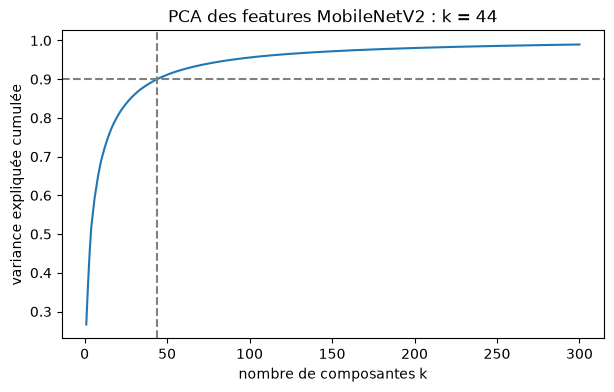

In [22]:
import matplotlib.pyplot as plt
plt.figure(figsize=(7, 4))
plt.plot(variance.k, variance.cumulative)
plt.axhline(THRESHOLD, linestyle="--", color="grey")
plt.axvline(k, linestyle="--", color="grey")
plt.xlabel("nombre de composantes k")
plt.ylabel("variance expliquée cumulée")
plt.title(f"PCA des features MobileNetV2 : k = {k}")
plt.show()

In [23]:
t0 = time.time()
pca_model = PCA(k=k, inputCol="features_centered", outputCol="pca_vec").fit(centered)
pca_df = (pca_model.transform(centered)
          .withColumn("pca_features", vector_to_array("pca_vec"))
          .select("path", "label", "pca_features"))
pca_df.write.mode("overwrite").parquet(PATH_PCA)
centered.unpersist()
seconds_pca = round(time.time() - t0, 1)
variance_kept = float(pca_model.explainedVariance.toArray().sum())
print(f"PCA écrite en {seconds_pca} s ; variance conservée : {variance_kept:.1%}")

PCA écrite en 5.3 s ; variance conservée : 90.0%


## 3.8 Chargement des données enregistrées et validation du résultat

<u>Correction</u> : la version précédente chargeait **tout** le résultat dans un DataFrame pandas, c'est-à-dire
dans la mémoire du seul driver. Cela ne passe pas à l'échelle. Ici, Spark relit et compte les résultats
de façon distribuée, et seules **5 lignes** sont converties en pandas pour l'affichage.

In [24]:
result = spark.read.parquet(PATH_PCA)
result.printSchema()
n_result = result.count()
df = result.limit(5).toPandas()
print("lignes :", n_result, "| attendu :", n_images)

root
 |-- path: string (nullable = true)
 |-- label: string (nullable = true)
 |-- pca_features: array (nullable = true)
 |    |-- element: double (containsNull = true)

lignes : 1492 | attendu : 1492


<u>On affiche les 5 premières lignes du DataFrame</u> :

In [25]:
df.head()

,path,label,pca_features
0,file:/home/darya/p8/data/Test_local/Apple Gold...,Apple Golden 1,"[6.304877370849428, 6.438815036058987, 5.24565..."
1,file:/home/darya/p8/data/Test_local/Apple Gold...,Apple Golden 1,"[6.376100326705956, 6.275832291974627, 6.10536..."
2,file:/home/darya/p8/data/Test_local/Apple Gold...,Apple Golden 1,"[5.732399193604682, 6.0261115173659725, 5.6193..."
3,file:/home/darya/p8/data/Test_local/Apple Gold...,Apple Golden 1,"[6.629238138449983, 4.500832608637798, 4.34721..."
4,file:/home/darya/p8/data/Test_local/Apple Gold...,Apple Golden 1,"[6.924279345693306, 5.214067458832625, 5.12472..."


<u>On valide</u> que chaque image a bien **1280** features avant la PCA et **k** composantes après :

In [26]:
n_features = len(spark.read.parquet(PATH_Result).first()["features"])
print("features avant PCA :", n_features, "| après PCA :", len(df.loc[0, "pca_features"]), "| k =", k)
assert n_result == n_images and n_features == 1280 and len(df.loc[0, "pca_features"]) == k

features avant PCA : 1280 | après PCA : 44 | k = 44


<u>Résumé de l'exécution locale</u> (à reporter dans la présentation) :

In [27]:
print(f"images : {n_images} | classes : {n_labels} | cœurs : {sc.defaultParallelism}")
print(f"extraction : {seconds_features} s | PCA : {seconds_pca} s | k = {k} | variance conservée : {variance_kept:.1%}")

images : 1492 | classes : 10 | cœurs : 4
extraction : 17.0 s | PCA : 5.3 s | k = 44 | variance conservée : 90.0%


Nous venons de valider le processus sur un jeu de données allégé en local, où nous avons simulé un cluster
en répartissant la charge sur les cœurs d'une même machine.

Nous allons maintenant déployer **toute la chaîne** (extraction des features **et** PCA) sur un réel cluster
de machines, sur la totalité du dossier "Test".

# 4. Déploiement de la solution sur le cloud

Nous déployons maintenant **toute la chaîne de traitement** (chargement, extraction des features avec diffusion
des poids, PCA, écriture des résultats) sur un cluster de machines dans le cloud, en respectant le **RGPD**.

## 4.1 Les briques d'une architecture Big Data

Une architecture Big Data se compose de briques indépendantes, chacune avec un rôle précis :

| Brique | Rôle | Outil AWS retenu |
|---|---|---|
| Stockage distribué et durable | conserver les images, le code, les résultats, indépendamment des machines de calcul | **Amazon S3** |
| Calcul distribué | répartir les traitements sur plusieurs machines | **Amazon EMR** (machines **EC2** + Hadoop/**YARN** + **Spark**) |
| Gestion des identités et des accès | décider qui (personne ou service) peut faire quoi | **AWS IAM** |
| Environnement de travail | exécuter et présenter le notebook sur le cluster | **JupyterHub** + **Livy** (installés par EMR) |
| Installation des dépendances | installer les mêmes librairies sur toutes les machines | **action d'amorçage** (bootstrap) EMR |
| Supervision | suivre l'exécution des tâches, retrouver les erreurs | **Spark History Server**, journaux dans S3 |
| Maîtrise des coûts | ne payer que le temps utile | **AWS Budgets**, résiliation automatique du cluster |

## 4.2 Choix des outils : AWS EMR et S3

**AWS** permet de louer de la puissance de calcul à la demande : si le volume d'images augmente fortement,
il suffit d'ajouter des machines au cluster.

Deux solutions étaient possibles :
- **IaaS** (instances EC2 nues) : liberté totale, mais il faut installer et maintenir Java, Spark, Jupyter
  sur chaque machine ;
- **PaaS** (**EMR**) : un cluster avec Spark, YARN et JupyterHub déjà installés et configurés, recréé
  à l'identique en 15 à 20 minutes.

Nous retenons **EMR**, plus rapide et plus fiable à mettre en œuvre. Les données sont stockées dans **S3** et
non sur les disques des machines, qui sont **effacés à la résiliation** du cluster.
D'autres solutions existent : Databricks (autorisé par le brief, coût de licence en plus), EMR Serverless
(facturation par job, sans cluster à gérer).

## 4.3 Conformité au RGPD

Le RGPD impose ici que **les données soient stockées et traitées sur des serveurs situés sur le territoire
européen**. Toutes les ressources sont donc créées dans la région **eu-west-3 (Paris)** :

| Ressource | Mesure | Preuve |
|---|---|---|
| Bucket S3 | créé dans **eu-west-3** | `aws s3api get-bucket-location` (section 4.5) |
| Cluster EMR (calculs) | créé dans **eu-west-3** | nom des machines `*.eu-west-3.compute.amazonaws.com` (section 4.8) |
| Accès aux données | bucket **privé** (accès public bloqué) et **chiffré** (SSE-S3) | paramètres du bucket |
| Identités | utilisateur IAM dédié, accès limité au bucket du projet | politique IAM (section 4.4) |

<u>Remarque</u> : les images de fruits ne contiennent pas de données personnelles. Ces mesures anticipent
l'application réelle, où les photos des utilisateurs et leurs métadonnées (localisation, date) pourront en contenir.
Le choix d'une région européenne est nécessaire mais ne suffit pas à lui seul à la conformité RGPD complète
(contrat de traitement avec AWS, durée de conservation, journalisation des accès).

## 4.4 Configuration de l'environnement de travail

<u>Dans la console web</u> (seules étapes faites à la souris) :
1. création du compte AWS ;
2. **MFA** (double authentification) sur l'utilisateur racine ;
3. **budget** mensuel de 10 USD avec alertes par e-mail ;
4. utilisateur IAM **`p8-admin`** (MFA, console + clés d'accès pour la ligne de commande) ;
   en production, ses droits seraient limités au strict nécessaire (moindre privilège).

<u>Dans le terminal</u> : AWS CLI configurée avec la **région de Paris par défaut**, et un fichier de paramètres
chargé dans chaque terminal :

```bash
aws configure                      # clés de p8-admin ; région : eu-west-3 ; format : json
aws sts get-caller-identity        # vérification : ...:user/p8-admin

cat > ~/p8/aws.env <<'EOF'
export AWS_REGION=eu-west-3
export AWS_DEFAULT_REGION=eu-west-3
export BUCKET=<nom-du-bucket>
EOF
source ~/p8/aws.env
```

Les clés restent dans `~/.aws/credentials`, jamais dans ce notebook ni dans git.

## 4.5 Chargement des données sur S3

<u>Création du bucket à Paris</u> et vérification des trois propriétés exigées (région, pas d'accès public, chiffrement) :

```bash
aws s3api create-bucket --bucket $BUCKET --create-bucket-configuration LocationConstraint=eu-west-3
aws s3api get-bucket-location --bucket $BUCKET          # "LocationConstraint": "eu-west-3"
aws s3api get-public-access-block --bucket $BUCKET      # 4 x true
aws s3api get-bucket-encryption --bucket $BUCKET        # "SSEAlgorithm": "AES256"
```

<u>Envoi des images</u> du dossier **Test** et contrôle du nombre de fichiers :

```bash
aws s3 sync "data/fruits-360/Test" s3://$BUCKET/Test --only-show-errors
aws s3 ls s3://$BUCKET/Test/ --recursive --summarize | tail -2    # Total Objects = nombre local
```

<!-- Capture à insérer : sortie des quatre commandes de vérification -->

## 4.6 Configuration du serveur EMR

<u>Le script d'amorçage</u> `bootstrap-emr.sh` (fourni avec ce notebook) s'exécute sur **chaque machine**
du cluster au démarrage, avant Spark. Il installe **les mêmes versions qu'en local** (section 3.3) :

```bash
#!/bin/bash
set -euxo pipefail
python3 --version
python3 -m pip --version || sudo dnf install -y python3-pip
sudo python3 -m pip install tensorflow-cpu==2.16.2 keras==3.5.0 numpy==1.26.4 \
                            pandas==2.2.3 pyarrow==17.0.0 pillow==10.4.0
python3 -c "import tensorflow as tf; print('bootstrap OK', tf.__version__)"
```

Installer les librairies depuis le notebook ne les installerait que sur la machine principale :
les exécuteurs échoueraient avec `ModuleNotFoundError: tensorflow`.
`set -euxo pipefail` arrête le script à la première erreur : la création du cluster échoue tout de suite,
au lieu d'un cluster qui démarre puis plante pendant la démonstration.

Envoi du script dans le bucket : `aws s3 cp bootstrap-emr.sh s3://<nom-du-bucket>/bootstrap-emr.sh`

<u>Préparatifs (une seule fois)</u> : envoi du script, clé SSH, rôles EMR, fichier de configuration.

```bash
aws s3 cp bootstrap-emr.sh s3://$BUCKET/bootstrap-emr.sh
aws ec2 create-key-pair --key-name p8-emr-key --key-type rsa --key-format pem \
    --query KeyMaterial --output text > ~/.ssh/p8-emr-key.pem
chmod 400 ~/.ssh/p8-emr-key.pem
aws emr create-default-roles

cat > ~/p8/emr-config.json <<EOF
[
  {"Classification": "jupyter-s3-conf",
   "Properties": {"s3.persistence.enabled": "true", "s3.persistence.bucket": "$BUCKET"}},
  {"Classification": "spark-defaults",
   "Properties": {"spark.sql.execution.arrow.maxRecordsPerBatch": "256"}}
]
EOF
```

<u>Création du cluster</u> (dernière version EMR 7 : `aws emr list-release-labels --filters Prefix=emr-7`) :

```bash
CLUSTER_ID=$(aws emr create-cluster \
  --name p8-fruits \
  --release-label <version-emr-7> \
  --applications Name=Hadoop Name=Spark Name=Livy Name=JupyterHub \
  --instance-groups InstanceGroupType=MASTER,InstanceCount=1,InstanceType=m5.xlarge \
                    InstanceGroupType=CORE,InstanceCount=2,InstanceType=m5.xlarge \
  --use-default-roles \
  --ec2-attributes KeyName=p8-emr-key \
  --bootstrap-actions Path=s3://$BUCKET/bootstrap-emr.sh,Name=install-python-libs \
  --configurations file://$HOME/p8/emr-config.json \
  --log-uri s3://$BUCKET/logs/ \
  --auto-termination-policy IdleTimeout=3600 \
  --query ClusterId --output text)
```

| Option | Rôle |
|---|---|
| `--release-label` | Spark 3.5, Java 17, Python 3.9, comme en local |
| `--applications` | Hadoop (YARN), Spark, Livy (relie JupyterHub à Spark), JupyterHub |
| `--instance-groups` | 1 machine primaire + 2 machines principales `m5.xlarge` (même matériel que l'alternant) |
| `--use-default-roles` | rôle de service (EMR crée les machines) et profil d'instance (accès à S3) |
| `--bootstrap-actions` | installation des librairies sur toutes les machines |
| `--configurations` | notebooks enregistrés dans S3, lots Arrow de 256 images |
| `--log-uri` | journaux conservés dans S3 après la résiliation |
| `--auto-termination-policy` | résiliation automatique après 1 h d'inactivité |
| (pas de `--region`) | région de `aws.env` : **eu-west-3 (Paris)** |

## 4.7 Instanciation du serveur

```bash
aws emr wait cluster-running --cluster-id $CLUSTER_ID
aws emr describe-cluster --cluster-id $CLUSTER_ID --query Cluster.Status.State --output text   # WAITING
```

Le statut passe par STARTING → BOOTSTRAPPING → RUNNING → **WAITING** (prêt), en 10 à 20 minutes.
**La facturation commence dès la création.**
En cas d'échec, la raison est affichée dans le résumé du cluster et le journal du script d'amorçage
se trouve dans `s3://<nom-du-bucket>/logs/<id-du-cluster>/node/<id-machine>/bootstrap-actions/`.

## 4.8 Création du tunnel SSH vers la machine primaire

JupyterHub et le Spark History Server ne sont accessibles que depuis le réseau du cluster.

1. **Pare-feu** : autoriser SSH **uniquement depuis notre adresse IP**. <br />
   <u>Correction</u> : la version précédente ouvrait le port 22 à **n'importe quelle adresse** (`0.0.0.0/0`).
2. **Tunnel** (terminal à garder ouvert).

```bash
SG=$(aws emr describe-cluster --cluster-id $CLUSTER_ID \
     --query Cluster.Ec2InstanceAttributes.EmrManagedMasterSecurityGroup --output text)
MYIP=$(curl -s https://checkip.amazonaws.com)
aws ec2 authorize-security-group-ingress --group-id $SG --protocol tcp --port 22 --cidr $MYIP/32

DNS=$(aws emr describe-cluster --cluster-id $CLUSTER_ID --query Cluster.MasterPublicDnsName --output text)
ssh -i ~/.ssh/p8-emr-key.pem -N -L 9443:localhost:9443 -L 18080:localhost:18080 hadoop@$DNS
```

Chaque `-L` relie un port du portable à un port de la machine primaire : 9443 pour JupyterHub,
18080 pour le Spark History Server. Aucune extension de navigateur (FoxyProxy) n'est nécessaire.
Le nom de la machine (`ec2-...eu-west-3.compute.amazonaws.com`) confirme que le calcul a lieu à Paris.

## 4.9 Connexion au notebook JupyterHub

Ouvrir **https://localhost:9443** (accepter l'avertissement de certificat), se connecter avec l'utilisateur
par défaut d'EMR **jovyan** / **jupyter**. Ce mot de passe par défaut n'est acceptable que parce que JupyterHub
n'est accessible que par le tunnel, lui-même limité à notre IP.

Grâce à la persistance S3, les notebooks sont enregistrés dans `s3://<nom-du-bucket>/jupyter/` et survivent
à la résiliation. Téléverser ce notebook (**Upload**), puis choisir le noyau **PySpark**.

## 4.10 Exécution du code

Le notebook s'exécute maintenant **sur le cluster EMR**, avec le noyau **PySpark** : chaque cellule est envoyée,
par **Livy**, à une application Spark qui tourne sur le cluster. La session `spark` et le contexte `sc` sont créés
par le noyau : la cellule `SparkSession.builder` de la partie locale n'est donc pas réutilisée.

Le code est **le même qu'en local** (sections 3.7 et 3.8, testées) ; seules changent :
- les **chemins**, qui pointent vers **S3** : les images sont lues dans S3 et **tous les résultats y sont écrits
  directement** (features, PCA, variance) ;
- la **taille des lots Arrow**, fixée par `spark.conf.set` (la session est créée par le noyau) ;
- le **graphique** de la variance, tracé sur le portable à partir du fichier écrit dans S3.

**Toute la chaîne de traitement, PCA comprise, est exécutée dans le cloud.**

### 4.10.1 Démarrage de la session Spark

In [ ]:
# L'exécution de cette cellule démarre l'application Spark

<u>Affichage des informations sur la session en cours et liens vers Spark UI</u> :

In [ ]:
%%info

### 4.10.2 Installation des packages

Les packages nécessaires ont été installé via l'étape de **bootstrap** à l'instanciation du serveur.

### 4.10.3 Import des librairies

In [ ]:
import io
import os
import time
from typing import Iterator

import numpy as np
import pandas as pd
from PIL import Image

import tensorflow as tf
from keras.applications.mobilenet_v2 import MobileNetV2, preprocess_input # type: ignore
from keras import Model

from pyspark.sql.functions import col, pandas_udf, element_at, split
from pyspark.ml.functions import array_to_vector, vector_to_array
from pyspark.ml.feature import StandardScaler, PCA

### 4.10.4 Définition des PATH pour charger les images et enregistrer les résultats

Nous accédons directement à nos **données sur S3** comme si elles étaient **stockées localement** :
EMR lit et écrit les chemins `s3://` (EMRFS). Les résultats sont donc **écrits directement dans S3**.

In [ ]:
BUCKET = "<nom-du-bucket>"       # bucket créé en section 4.5, région eu-west-3

PATH = 's3://' + BUCKET
PATH_Data = PATH+'/Test'
PATH_Result = PATH+'/Results'                 # features (1280 values)
PATH_PCA = PATH+'/Results_PCA'                # features after PCA
PATH_Variance = PATH+'/Results_PCA_variance'  # explained variance (CSV)
print('PATH:          '+PATH+
      '\nPATH_Data:     '+PATH_Data+
      '\nPATH_Result:   '+PATH_Result+
      '\nPATH_PCA:      '+PATH_PCA+
      '\nPATH_Variance: '+PATH_Variance)
print("Cœurs disponibles pour les exécuteurs :", sc.defaultParallelism)

### 4.10.5 Traitement des données

#### 4.10.5.1 Chargement des données

In [ ]:
images = spark.read.format("binaryFile") \
  .option("pathGlobFilter", "*.jpg") \
  .option("recursiveFileLookup", "true") \
  .load(PATH_Data)

In [ ]:
images.show(5)

<u>Je ne conserve que le **path** de l'image et j'ajoute <br />
    une colonne contenant les **labels** de chaque image</u> :

In [ ]:
images = images.withColumn('label', element_at(split(images['path'], '/'),-2))
print(images.printSchema())
print(images.select('path','label').show(5,False))

In [ ]:
n_images = images.count()   # action: Spark lists and reads the files now
n_labels = images.select("label").distinct().count()
print(n_images, "images,", n_labels, "classes")

#### 4.10.5.2 Préparation du modèle et diffusion des poids

Même code qu'en section 3.7.2 : le driver télécharge les poids **une seule fois**, les **diffuse** aux exécuteurs,
qui reconstruisent le modèle **sans téléchargement** (`weights=None`). Sur le cluster, les exécuteurs sont
réellement sur d'autres machines (les 2 machines principales) : la diffusion prend ici tout son sens.

In [ ]:
model = MobileNetV2(weights='imagenet',
                    include_top=True,
                    input_shape=(224, 224, 3))

In [ ]:
new_model = Model(inputs=model.input,
                  outputs=model.layers[-2].output)

In [ ]:
weights = new_model.get_weights()
bc_weights = sc.broadcast(weights)

print(len(weights), "tableaux de poids,",
      round(sum(w.nbytes for w in weights) / 1e6, 1), "Mo diffusés")

In [ ]:
new_model.summary()

In [ ]:
def model_fn():
    """
    Executed on each executor: rebuilds MobileNetV2 without its last layer,
    WITHOUT downloading anything, and loads the broadcast weights.
    """
    model = MobileNetV2(weights=None,          # architecture only: no download
                        include_top=True,
                        input_shape=(224, 224, 3))
    new_model = Model(inputs=model.input,
                      outputs=model.layers[-2].output)
    new_model.set_weights(bc_weights.value)    # local copy of the broadcast weights
    return new_model

In [ ]:
test_images = np.random.rand(2, 224, 224, 3).astype("float32")
same = np.allclose(new_model.predict(test_images, verbose=0),
                   model_fn().predict(test_images, verbose=0), atol=1e-5)
print("Modèle reconstruit à partir des poids diffusés identique :", same)

#### 4.10.5.3 Définition du processus de chargement des images <br/> et application de leur featurisation à travers l'utilisation de pandas UDF

In [ ]:
def preprocess(content):
    """
    Preprocesses raw image bytes for prediction.
    """
    img = Image.open(io.BytesIO(content)).convert("RGB").resize([224, 224])
    arr = np.asarray(img, dtype=np.float32)
    return preprocess_input(arr)

def featurize_series(model, content_series):
    """
    Featurize a pd.Series of raw images using the input model.
    :return: a pd.Series of image features
    """
    input = np.stack(content_series.map(preprocess).to_list())
    preds = model.predict(input, verbose=0)
    output = [p.flatten().astype(np.float32) for p in preds]
    return pd.Series(output)

@pandas_udf('array<float>')
def featurize_udf(content_series_iter: Iterator[pd.Series]) -> Iterator[pd.Series]:
    """
    Scalar iterator pandas UDF: the model is rebuilt ONCE per task from the
    broadcast weights, then reused for every batch of images.
    """
    model = model_fn()
    for content_series in content_series_iter:
        yield featurize_series(model, content_series)

#### 4.10.5.4 Exécutions des actions d'extractions de features

In [ ]:
spark.conf.set("spark.sql.execution.arrow.maxRecordsPerBatch", "256")
print("Images par lot Arrow :", spark.conf.get("spark.sql.execution.arrow.maxRecordsPerBatch"))

In [ ]:
features_df = images.repartition(2 * sc.defaultParallelism).select(col("path"),
                                            col("label"),
                                            featurize_udf("content").alias("features")
                                           )

In [ ]:
print(PATH_Result)

In [ ]:
t0 = time.time()
features_df.write.mode("overwrite").parquet(PATH_Result)
seconds_features = round(time.time() - t0, 1)
print(f"Extraction des features : {seconds_features} s")

#### 4.10.5.5 Réduction de dimension (PCA) sur le cluster

Mêmes cellules qu'en section 3.7.5, exécutées **sur le cluster** et **écrivant dans S3**.
Le graphique de la variance est tracé ensuite sur le portable, à partir du fichier CSV écrit dans S3 :

```bash
aws s3 cp --recursive s3://<nom-du-bucket>/Results_PCA_variance data/variance_emr
```

In [ ]:
features = spark.read.parquet(PATH_Result).withColumn("features_vec", array_to_vector("features"))

scaler = StandardScaler(inputCol="features_vec", outputCol="features_centered",
                        withMean=True, withStd=False).fit(features)
centered = scaler.transform(features).cache()   # reused by several actions below
n_rows = centered.count()
print(n_rows, "vecteurs centrés")

In [ ]:
K_MAX = int(min(300, n_rows - 1, 1280))   # at most n-1 components carry variance
pca_full = PCA(k=K_MAX, inputCol="features_centered", outputCol="pca_tmp").fit(centered)

explained = pca_full.explainedVariance.toArray()
variance = pd.DataFrame({"k": np.arange(1, K_MAX + 1),
                         "explained": explained,
                         "cumulative": np.cumsum(explained)})
THRESHOLD = 0.90
k = int(variance.loc[variance.cumulative >= THRESHOLD, "k"].min()
        if (variance.cumulative >= THRESHOLD).any() else K_MAX)
print(f"k = {k} composantes conservent {variance.cumulative.iloc[k - 1]:.1%} de la variance")

(spark.createDataFrame(variance).coalesce(1)
      .write.mode("overwrite").csv(PATH_Variance, header=True))

In [ ]:
t0 = time.time()
pca_model = PCA(k=k, inputCol="features_centered", outputCol="pca_vec").fit(centered)
pca_df = (pca_model.transform(centered)
          .withColumn("pca_features", vector_to_array("pca_vec"))
          .select("path", "label", "pca_features"))
pca_df.write.mode("overwrite").parquet(PATH_PCA)
centered.unpersist()
seconds_pca = round(time.time() - t0, 1)
variance_kept = float(pca_model.explainedVariance.toArray().sum())
print(f"PCA écrite en {seconds_pca} s ; variance conservée : {variance_kept:.1%}")

In [ ]:
print(variance.head(10).to_string(index=False))

### 4.10.6 Chargement des données enregistrées et validation du résultat

Comme en section 3.8 : Spark relit les résultats **depuis S3** et les compte ; seules 5 lignes vont en pandas.

In [ ]:
result = spark.read.parquet(PATH_PCA)
result.printSchema()
n_result = result.count()
df = result.limit(5).toPandas()
print("lignes :", n_result, "| attendu :", n_images)

In [ ]:
df[['path', 'label']]

In [ ]:
n_features = len(spark.read.parquet(PATH_Result).first()["features"])
print("features avant PCA :", n_features, "| après PCA :", len(df.loc[0, "pca_features"]), "| k =", k)
assert n_result == n_images and n_features == 1280 and len(df.loc[0, "pca_features"]) == k

In [ ]:
print(f"images : {n_images} | classes : {n_labels} | cœurs : {sc.defaultParallelism}")
print(f"extraction : {seconds_features} s | PCA : {seconds_pca} s | k = {k} | variance conservée : {variance_kept:.1%}")

<u>Résultats dans S3</u> : les dossiers `Results`, `Results_PCA` et `Results_PCA_variance` contiennent des fichiers
`part-...` et un marqueur `_SUCCESS` (écriture complète).

```bash
aws s3 ls s3://<nom-du-bucket>/ --recursive | grep _SUCCESS
```

<!-- Capture à insérer : bucket S3 avec Test/ et les dossiers de résultats -->

## 4.11 Suivi de l'exécution avec le Spark History Server

Ouvrir **http://localhost:18080** (tunnel de la section 4.8), cocher *Show incomplete applications* pendant
l'exécution, puis ouvrir l'application :
- onglet **Jobs** : une tâche par action (`count`, `write`, ajustement de la PCA...) ;
- onglet **Stages** : l'étape d'extraction, ses tâches (une par partition) et leur durée ;
- onglet **Executors** : les exécuteurs des **deux machines principales** et les tâches de chacun.
  **C'est la preuve que le traitement est réparti sur plusieurs machines.**

<!-- Captures à insérer : Jobs, Stages, Executors -->

Pour comparaison, l'alternant avait mesuré un peu moins de 8 minutes pour l'extraction des 22 688 images
sur le même matériel. Reporter ici la durée mesurée par la cellule d'extraction.

## 4.12 Résiliation de l'instance EMR

Le cluster EMR est **facturé à la minute, même au repos** (environ 0,8 USD par heure pour 3 machines `m5.xlarge`,
valeur approximative à vérifier sur la page de tarifs). Il faut le **résilier à la fin de chaque séance**.

1. Télécharger le notebook exécuté (*File → Download*) ; il est aussi conservé dans `s3://<nom-du-bucket>/jupyter/`.
2. Fermer le noyau (*File → Close and Halt*) et le tunnel SSH (`Ctrl+C`).
3. Résilier le cluster et vérifier qu'aucune machine ne tourne :

```bash
aws emr terminate-clusters --cluster-ids $CLUSTER_ID
aws emr wait cluster-terminated --cluster-id $CLUSTER_ID
aws emr list-clusters --active          # {"Clusters": []}
aws ec2 describe-instances --filters Name=instance-state-name,Values=running \
    --query 'Reservations[].Instances[].InstanceId'                     # []
```

4. Le lendemain : **Facturation → Factures** : seules des lignes EMR, EC2 et quelques centimes de S3.

Ce qui est perdu : les disques du cluster. Ce qui est conservé : tout ce qui est dans **S3**
(images, résultats, notebooks, journaux, script d'amorçage).

Filets de sécurité : la **résiliation automatique après 1 h d'inactivité** (section 4.6) et les **budgets** (section 4.4).

## 4.13 Recréer le cluster (si besoin)

Pour une nouvelle séance (ou la démonstration de soutenance), relancer la commande `aws emr create-cluster`
de la section 4.6 : elle recrée un cluster identique en 15 à 20 minutes. La règle SSH est conservée
(à refaire seulement si l'adresse IP a changé).

## 4.14 Arborescence du bucket S3 à la fin du projet

```
s3://<nom-du-bucket>/
├── Test/<variété>/<image>.jpg       images d'origine
├── bootstrap-emr.sh                  script d'amorçage
├── jupyter/                          notebooks (persistance JupyterHub)
├── logs/                             journaux du cluster
├── Results/                          features (Parquet, 1280 valeurs par image)
├── Results_PCA/                      features après PCA (Parquet, k valeurs par image)
└── Results_PCA_variance/             variance expliquée (CSV)
```

# 5. Conclusion

## 5.1 Synthèse

La chaîne de traitement a été développée et testée **en local** sur un extrait d'images, puis exécutée
**intégralement sur un cluster AWS EMR à Paris** sur tout le dossier Test :
chargement des images depuis S3, extraction des features avec MobileNetV2 et **diffusion des poids**,
**réduction de dimension par PCA**, écriture de tous les résultats **dans S3**.

<u>Améliorations apportées au travail de l'alternant</u> :

| Version précédente | Version actuelle |
|---|---|
| broadcast présent mais inutile (`weights='imagenet'` sur les exécuteurs) | exécuteurs reconstruits avec `weights=None` + poids diffusés, vérifié par une cellule |
| pas de PCA | PCA centrée, k choisi pour conserver 90 % de la variance, exécutée sur le cluster |
| `master('local')` : un seul cœur | `local[*]` : tous les cœurs |
| taille des lots Arrow en commentaire | 256 images par lot |
| validation en chargeant tout dans pandas | validation distribuée, 5 lignes en pandas |
| région implicite | eu-west-3 explicite et vérifiée pour le stockage et les calculs |
| SSH ouvert à toutes les adresses | SSH limité à notre adresse IP |
| EMR 6.3, TensorFlow 2.5 | EMR 7, versions figées identiques en local et sur le cluster |

## 5.2 Traitements critiques lors du passage à l'échelle

| Traitement | Pourquoi il devient critique quand le volume augmente | Mesure prise / piste |
|---|---|---|
| Décodage et inférence MobileNetV2 | coût proportionnel au nombre d'images, sur CPU | pandas UDF par lots, modèle construit une fois par tâche ; piste : GPU |
| Diffusion du modèle | sans broadcast : copie dans chaque tâche ou téléchargement par chaque machine | broadcast : une copie par exécuteur |
| Mémoire des lots Arrow | un lot de 10 000 images décodées dépasse la mémoire | 256 images par lot |
| Répartition (`repartition`) | déplacement des données entre machines (shuffle), déséquilibre des tâches | 2 partitions par cœur, adapté à la taille du cluster |
| Lecture de milliers de petits fichiers | ouvrir chaque fichier dans S3 coûte plus que le lire | piste : regrouper les images en fichiers Parquet |
| PCA | ajustement sur toutes les données | distribuée (Spark ML) ; matrice de covariance 1280 x 1280 seulement |
| Collecte vers le driver | `toPandas()` sur tout le résultat sature la mémoire du driver | validation distribuée, 5 lignes collectées |

## 5.3 Regard critique

- **Coût et temps** : à reporter (durée d'extraction, durée de la PCA, heures de cluster, coût total).
- **Qualité des features non évaluée** : aucun classifieur n'a encore été entraîné sur les composantes.
- **Exploitation** : notebook interactif via tunnel SSH ; pour la production, des jobs `spark-submit`
  (étapes EMR) ou EMR Serverless.
- **Sécurité** : utilisateur administrateur pour la console, mot de passe JupyterHub par défaut, profil
  d'instance EMR aux droits S3 larges ; à restreindre en production.
- **Alternatives** : Databricks (exploitation plus simple, coût de licence), EMR Serverless (facturation par job).

## 5.4 Correspondance avec le référentiel d'évaluation

| Critère | Où le trouver |
|---|---|
| C1-CE1 Briques d'architecture Big Data | section 4.1 |
| C1-CE2 Outils cloud conformes au RGPD | sections 4.2, 4.3 |
| C2-CE1 Fichiers de départ et transformés dans un stockage cloud conforme | sections 4.5, 4.10.5, 4.14 |
| C2-CE2 Scripts exécutés sur des machines du cloud | sections 4.6 à 4.10, 4.11 (Executors) |
| C2-CE3 Sorties écrites directement dans le stockage cloud | sections 4.10.4, 4.10.5 (`s3://`) |
| C3-CE1 Traitements critiques au passage à l'échelle | section 5.2 |
| C3-CE2 Données et traitements sur des serveurs européens | sections 4.3, 4.5, 4.8 |
| C3-CE3 Scripts s'appuyant sur Spark | sections 3.6 à 3.8, 4.10 |
| C3-CE4 Toute la chaîne exécutée dans le cloud | section 4.10 (extraction **et** PCA sur EMR) |